# NPE and experimental design

The network and hyperparameters are found using Optuna. The same hyperparameters were then applied to other feature blocks to avoid the compute cost.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

We use a Masked Autoregressive Flow with 5 transform layers and 64 hidden features
per layer, a batch size of 64, and learning rate 1.6488693479340492×10^-4. Input
scalers use training rows. The empirical simulation mass distribution supplies the
effective single-round training prior. The declared [11.5,14.5] log-mass box bounds
posterior sampling; it does not turn the empirical training sample into a uniform prior.

For scalar target parameters, the affine MAF reduces to a conditional Gaussian
distribution in log-mass space before any explicit support restriction. It cannot represent
arbitrary multimodal specialist mixtures.

### Two experiment families

The **block grid** uses `[r,vr,vt,log_bound_mass_ratio]` as its core. Chemistry adds
metallicity difference, photometry adds mean/difference g-r, and morphology adds
mean/difference dispersion and κcorot. Five blocks × three FLAMINGO host splits plus
five full-sample TNG fits give 20 models.

The **final six** use `[r,vr,vt]` or those three plus `log10(Mstar,a+Mstar,b)`, crossed
with FLAMINGO, TNG300 and balanced combined training. These baseline definitions
differ; their scores should not be treated as a single ablation series.


,best recorded trial
number,22
value,0.511668
datetime_start,2026-07-08 22:52:33.386769
datetime_complete,2026-07-08 23:13:42.461584
duration,0 days 00:21:09.074815
params_batch_size,64
params_hidden_features,64
params_learning_rate,0.000165
params_num_layers,2
params_num_transforms,5


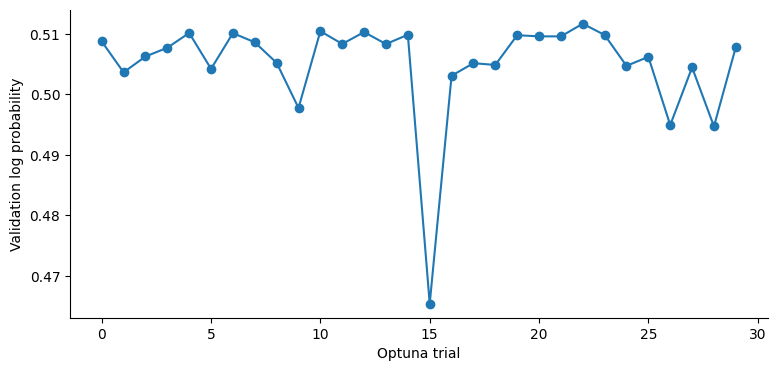

,domain,split,n,same_host,different_host,components,target_min,target_max
0,flamingo,train,109150,48301,60849,105997,11.544068,13.864985
1,flamingo,validation,12154,5306,6848,11778,11.608793,13.666518
2,flamingo,test,21409,9464,11945,20784,11.688531,13.600319
3,tng,train,1169,958,211,1162,11.959418,13.865908
4,tng,validation,130,112,18,130,12.101708,13.750499
5,tng,test,231,183,48,229,12.073711,13.735400


,n_rows,components,largest_rows,median_rows,largest_percent
flamingo_full,142713.0,138559.0,4.0,1.0,0.002803
flamingo_same_host,63071.0,63071.0,1.0,1.0,0.001586
flamingo_different_host,79642.0,77585.0,3.0,1.0,0.003767
flamingo_train,109150.0,105997.0,4.0,1.0,0.003665
flamingo_validation,12154.0,11778.0,3.0,1.0,0.024683
flamingo_test,21409.0,20784.0,4.0,1.0,0.018684
tng_full,1530.0,1521.0,2.0,1.0,0.130719
tng_same_host,1253.0,1253.0,1.0,1.0,0.079808
tng_different_host,277.0,277.0,1.0,1.0,0.361011
tng_train,1169.0,1162.0,2.0,1.0,0.171086


In [2]:
trials=table('training/optuna_trials.csv')
display(trials.loc[trials.value.idxmax()].to_frame('best recorded trial'))
fig,ax=plt.subplots(); ax.plot(trials.number,trials.value,'o-')
ax.set(xlabel='Optuna trial',ylabel='Validation log probability');plt.show()
display(table('final_six/split_counts.csv'))
display(pd.DataFrame(saved_json('populations/calculated_tables.json')['components']).T)

The Optuna search had 30 trials. `num_layers` was included in the search but was not
wired into the estimator; it is not an independently optimized effective parameter.
The hyperparameters were tuned on the earlier dynamics experiment and reused.

### Connected host components and balanced training

We construct a graph where nodes are host halos and edges connect host-i and host-j.
Hosts linked through a chain of pairs stay together. The train/validation/test split is
train/validation/test = 109150/12154/21409 for FLAMINGO and 1169/130/231 for TNG.
The TNG test has 183 same-host and 48 different-host pairs.

Combined batches draw 32 rows per simulation with replacement, minimizing an
equal-domain conditional log loss. Validation losses are weighted equally by domain.
Equal training weights do not imply a 50/50 conditional posterior at every input.


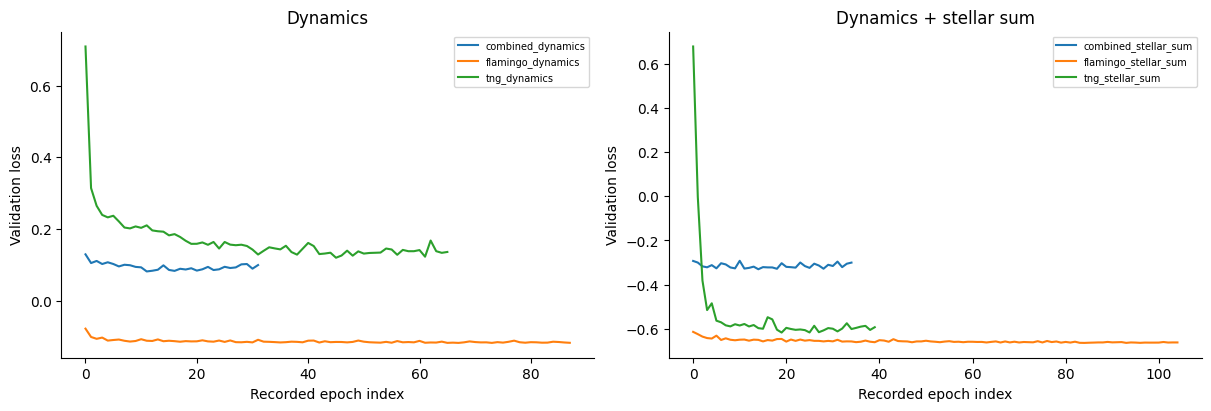

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for path in sorted((ROOT/'results/training').glob('*.csv')):
    if path.name == 'optuna_trials.csv': continue
    h=pd.read_csv(path)
    numeric=[c for c in h if 'validation' in c and pd.api.types.is_numeric_dtype(h[c])]
    if numeric:
        ax=axes[1 if 'stellar' in path.stem else 0]
        ax.plot(np.arange(len(h)),h[numeric[0]],label=path.stem)
for ax,title in zip(axes,['Dynamics','Dynamics + stellar sum']):
    ax.set(title=title,xlabel='Recorded epoch index',ylabel='Validation loss'); ax.legend(fontsize=7)
plt.show()

Implementation: [splitting](../research/src/lg_npe/splitting.py),
[training](../research/src/lg_npe/controlled_training.py),
[features](../research/src/lg_npe/features.py),
[final design](../research/src/lg_npe/final_design.py),
[block training and Optuna](../research/notebooks/original/inference_npe.ipynb),
[final-six workflow](../research/notebooks/original/final_six_model_experiment.ipynb).
Full refitting is optional and needs the research environment and generated caches.


[Previous](02_features_and_population_shift.ipynb) · [Next](04_within_and_cross_simulation.ipynb) · [Repository map](../README.md)
